## InterConRank Experiments

This Jupyter Notebook contains the experiments for the paper <br> ***InterConRank: Joint Node Centrality in Interconnected Heterogeneous Networks***.

Run *Setup*, then choose a dataset section. *Run All Cells* runs all 29 dataset–method comparisons. Each section reads the original files from `data/<dataset>/raw/` and downloads any missing files. The first run across all four datasets needs about 7.68 GB of downloads if the folders are empty.

Each section rebuilds the graph and evaluation references, displays its per-target measurements, and writes the unrounded values to `results/<dataset>/`. Rerunning a section replaces that dataset’s results. Use `graph_counts.csv` for Table 1 and `per_target_metrics.csv` for Tables 2 and 3.

### 0. Setup

In [1]:
import sys
from pathlib import Path

from IPython.display import display
from tqdm.auto import tqdm

# Jupyter can start in the project root or the notebooks folder.
ROOT = Path(".") if Path("data/sources.json").is_file() else Path("..")
sys.path.insert(0, str(ROOT))

from data import prepare_dataset
from experiments.outputs import save_dataset_results
from experiments.ranking import run_rankings

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")

#### Shared procedure

InterConRank uses the weights selected on VisPubData ($\lambda=0.51$, $\delta=0.43$) and uniform priors on each layer. Spearman’s correlation uses average ranks for ties. Hits@25% selects $K=\lceil N/4\rceil$ eligible nodes per target, breaking cutoff ties by ascending source ID. Known zero reference values participate in evaluation.

`AvgHits@25%` gives each author target a weight of one quarter and the paper target a weight of one half. AMiner uses the mean of its two author hit rates. The CSVs include the regenerated reference values aligned by source ID and the time taken by each ranking method.

In [2]:
def run_experiment(dataset):
    with tqdm(total=3, desc=dataset, unit="stage") as stages:
        stages.set_postfix_str("prepare graph and references")
        blocks, author_refs, paper_refs = prepare_dataset(dataset, ROOT / "data" / dataset)
        stages.update()

        stages.set_postfix_str("rank both layers")
        scores, timings = run_rankings(dataset, blocks, show_progress=True)
        stages.update()

        stages.set_postfix_str("evaluate and export")
        metrics = save_dataset_results(
            dataset, ROOT / "results" / dataset, blocks, author_refs, paper_refs,
            scores, timings, display_figure=display,
        )
        stages.update()

    return metrics

### 1. VisPubData

The three September 2021 CSVs (5 MB) supply IEEE Xplore citation counts for papers and the two corpus-based author targets. This section runs all eleven methods and saves their pairwise agreement figure and matrices. Its per-target measurements supply the values for Table 2.

<https://hauser-net.net/download/VisPubDataEtc/index.html>

Graph and evaluation populations. All 6,135 authors and 3,394 papers receive scores and enter the pairwise correlations between methods. Three papers lack an IEEE Xplore citation count. Six authors wrote at least one of those papers. We exclude those authors from both author-reference comparisons because their citation records are incomplete. Comparisons with the IEEE references therefore use 6,129 authors and 3,391 papers, including records with known zero counts. For Hits@25%, this gives $K=1{,}533$ authors and $K=848$ papers.

VisPubData:   0%|          | 0/3 [00:00<?, ?stage/s]

VisPubData — using authors-unique-ext.csv
VisPubData — using papers.csv
VisPubData — using paper-to-paper-citations.csv
VisPubData — building the graph and evaluation references


VisPubData rankings:   0%|          | 0/11 [00:00<?, ?method/s]

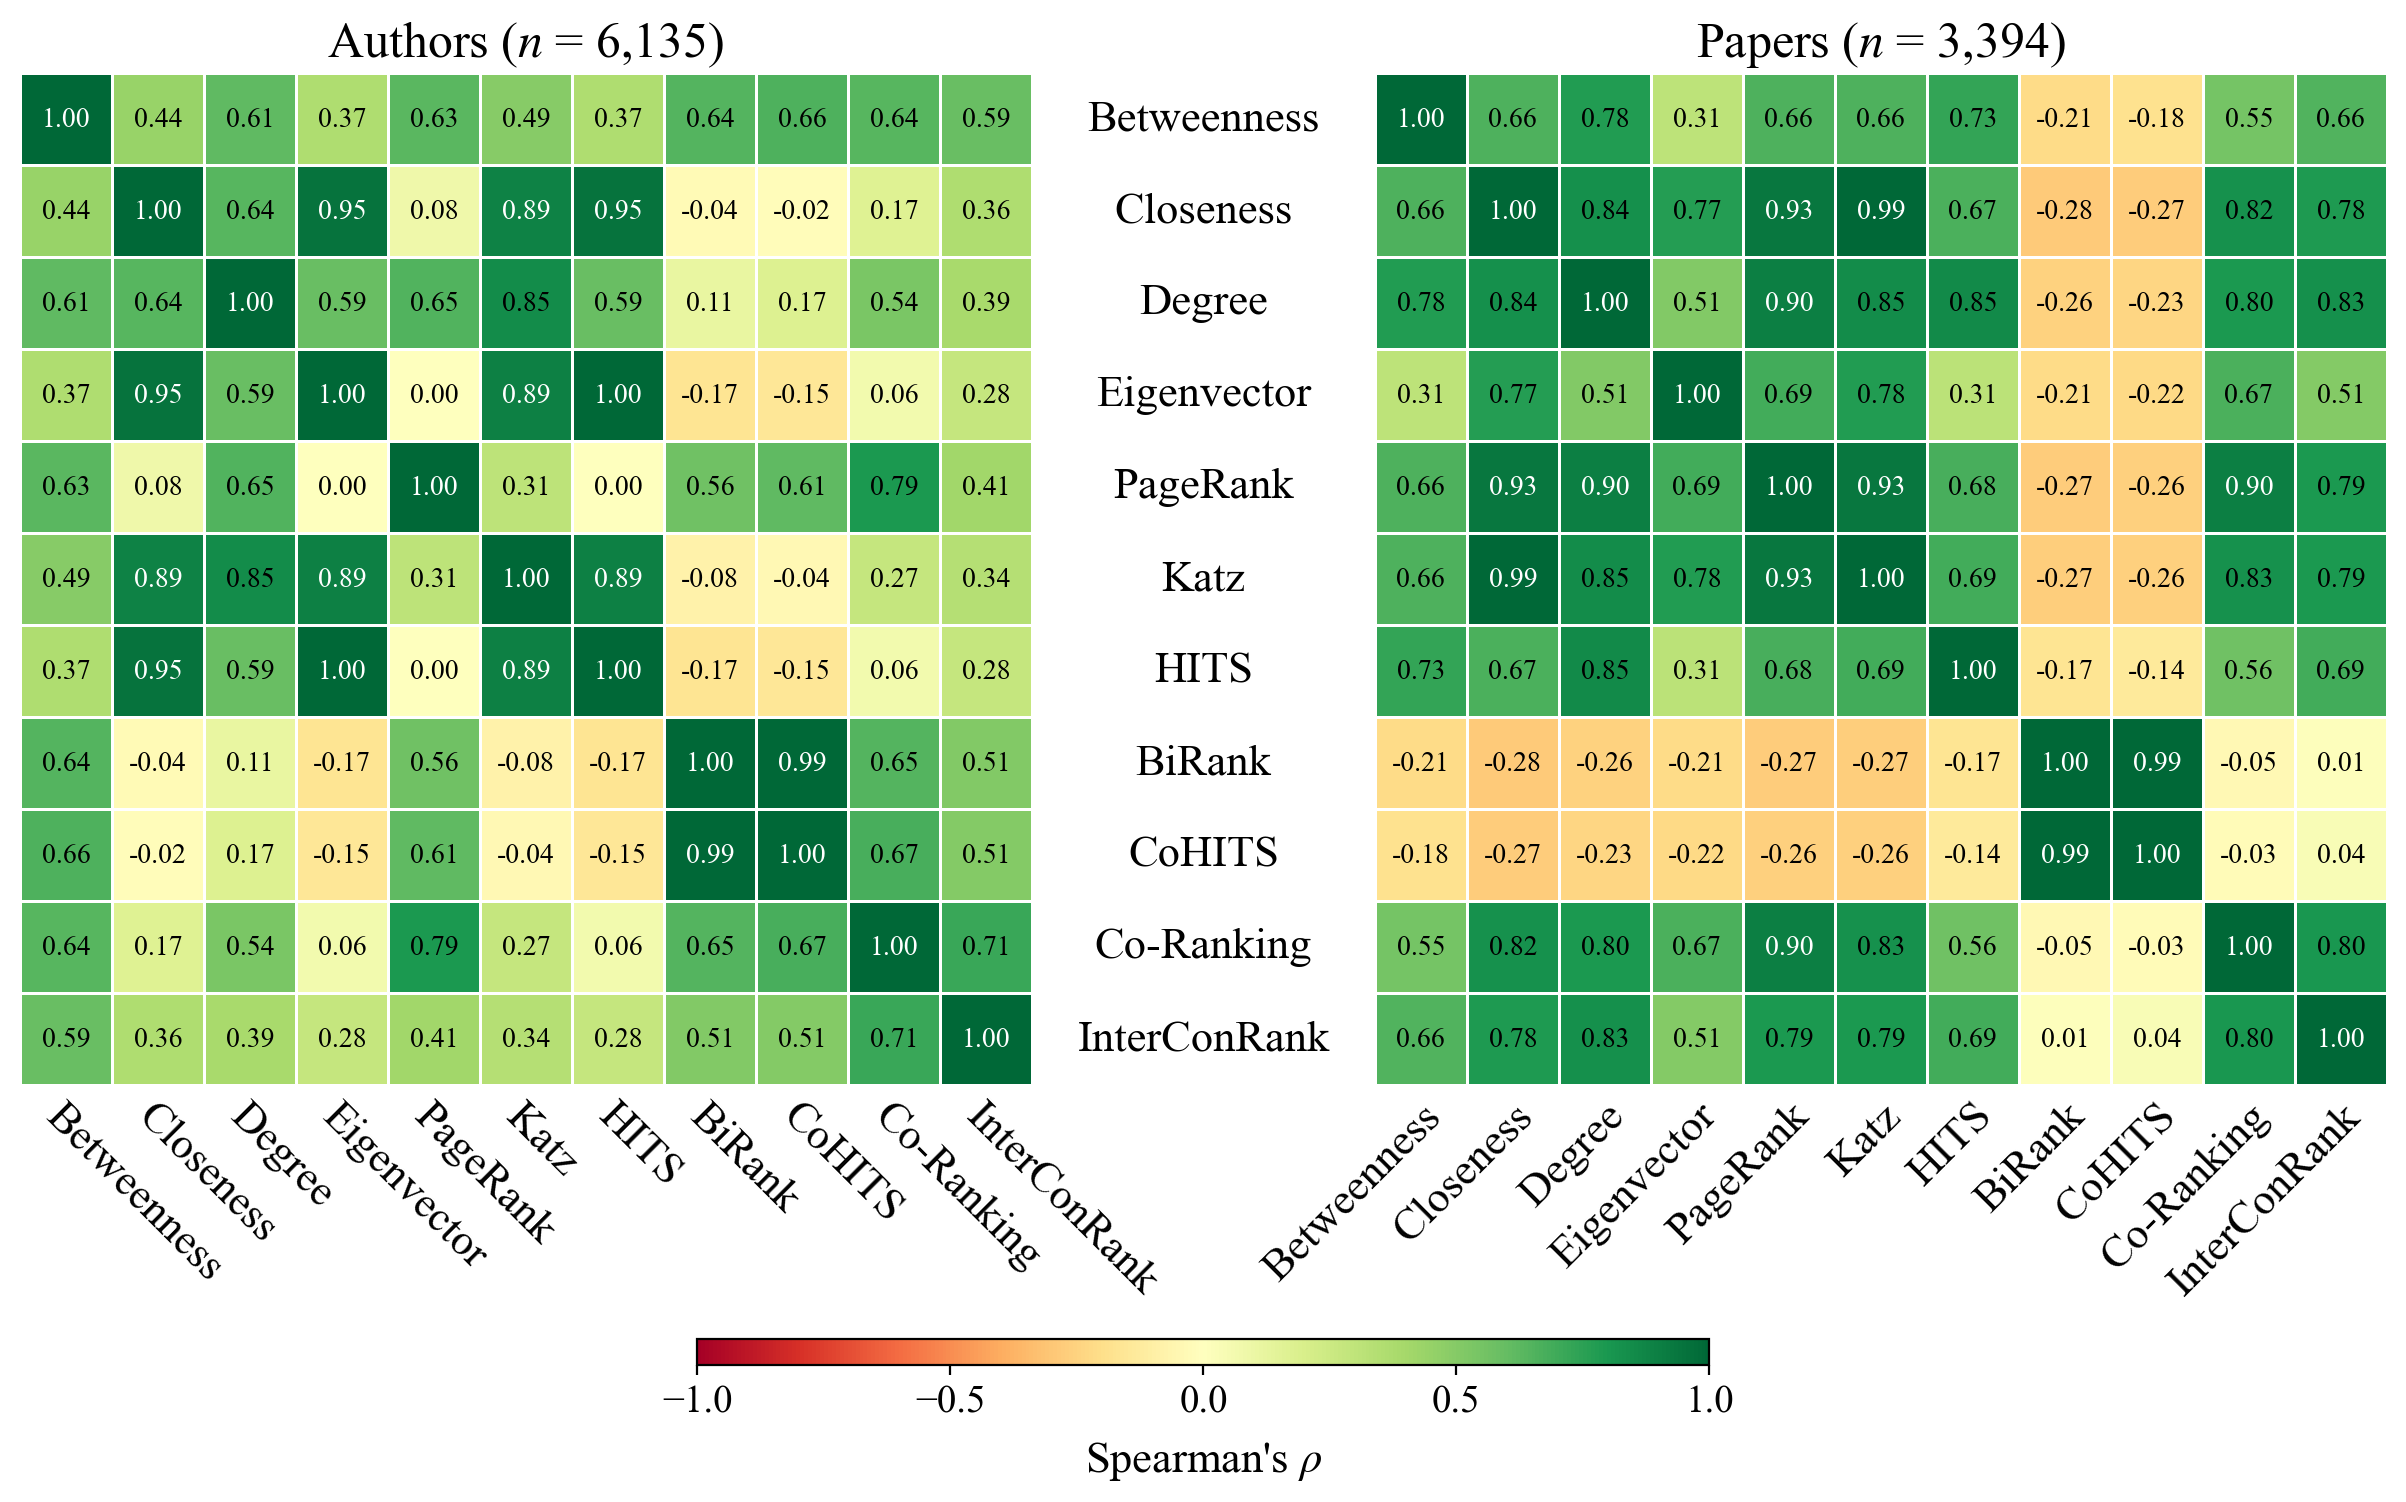

,Dataset,Method,Target,Nodes,Evaluated,K,Hits,Spearman,Hits@25%,ReferenceCutoff,ReferenceTieSize,ReferenceTieSelected,AvgHits@25%
0,VisPubData,Betweenness,Author h-index,6135,6129,1533,1176,0.679101,76.712329,1.0,3811,50,60.688055
1,VisPubData,Closeness,Author h-index,6135,6129,1533,961,0.438573,62.687541,1.0,3811,50,53.093461
2,VisPubData,Degree,Author h-index,6135,6129,1533,1037,0.475417,67.645140,1.0,3811,50,66.536780
3,VisPubData,Eigenvector,Author h-index,6135,6129,1533,753,0.342174,49.119374,1.0,3811,50,48.273863
4,VisPubData,PageRank,Author h-index,6135,6129,1533,1007,0.448114,65.688193,1.0,3811,50,59.729812
5,VisPubData,Katz,Author h-index,6135,6129,1533,874,0.427861,57.012394,1.0,3811,50,52.226681
6,VisPubData,HITS,Author h-index,6135,6129,1533,753,0.342174,49.119374,1.0,3811,50,51.045090
7,VisPubData,BiRank,Author h-index,6135,6129,1533,1086,0.590674,70.841487,1.0,3811,50,40.083993
8,VisPubData,CoHITS,Author h-index,6135,6129,1533,1124,0.593361,73.320287,1.0,3811,50,41.233084
9,VisPubData,Co-Ranking,Author h-index,6135,6129,1533,1119,0.602537,72.994129,1.0,3811,50,63.348895


In [3]:
vispub_metrics = run_experiment("VisPubData")
vispub_metrics

### 2. Semantic Scholar

The six compressed impact-prediction files (810 MB) provide the author and paper cohorts for the graph through 2005. The 2015 response fields supply the cumulative author h-index, author citations and paper citations. This section evaluates the six methods used on the larger graphs.

<https://github.com/Lucaweihs/impact-prediction>

In [4]:
scholar_metrics = run_experiment("SemanticScholar")
scholar_metrics

SemanticScholar:   0%|          | 0/3 [00:00<?, ?stage/s]

SemanticScholar — using paperIdToPaperData-1975-2015.json.gz
SemanticScholar — using citationGraph-1975-2015.json.gz
SemanticScholar — using authors-1975-2005-2015-2.tsv.gz
SemanticScholar — using paperIds-1975-2005-2015-2.tsv.gz
SemanticScholar — using authorResponses-1975-2005-2015-2.tsv.gz
SemanticScholar — using paperResponses-1975-2005-2015-2.tsv.gz
SemanticScholar — building the graph and evaluation references


SemanticScholar rankings:   0%|          | 0/6 [00:00<?, ?method/s]

,Dataset,Method,Target,Nodes,Evaluated,K,Hits,Spearman,Hits@25%,ReferenceCutoff,ReferenceTieSize,ReferenceTieSelected,AvgHits@25%
0,SemanticScholar,Degree,Author h-index,836024,836024,209006,119330,0.480773,57.094055,2.0,109483,44576,65.788599
1,SemanticScholar,PageRank,Author h-index,836024,836024,209006,112961,0.347003,54.046774,2.0,109483,44576,61.070970
2,SemanticScholar,BiRank,Author h-index,836024,836024,209006,116310,0.382758,55.649120,2.0,109483,44576,35.064680
3,SemanticScholar,CoHITS,Author h-index,836024,836024,209006,130996,0.414832,62.675713,2.0,109483,44576,39.066427
4,SemanticScholar,Co-Ranking,Author h-index,836024,836024,209006,134247,0.505080,64.231170,2.0,109483,44576,63.051417
5,SemanticScholar,InterConRank,Author h-index,836024,836024,209006,135687,0.527876,64.920146,2.0,109483,44576,62.195289
6,SemanticScholar,Degree,Author total citations,836024,836024,209006,118371,0.479577,56.635216,20.0,5509,5461,65.788599
7,SemanticScholar,PageRank,Author total citations,836024,836024,209006,109103,0.325698,52.200894,20.0,5509,5461,61.070970
8,SemanticScholar,BiRank,Author total citations,836024,836024,209006,109009,0.322150,52.155919,20.0,5509,5461,35.064680
9,SemanticScholar,CoHITS,Author total citations,836024,836024,209006,121758,0.356511,58.255744,20.0,5509,5461,39.066427


### 3. AMiner

The four Academic Social Network archives (787 MB) provide the author and paper layers. The experiment ranks both layers and evaluates authors against the supplied h-index and total citations. The paper-reference column is empty because the source provides author impact measures only.

<https://www.aminer.cn/aboutus/en-US/articles/55af4228dabfae1ce3ed1253>

In [5]:
aminer_metrics = run_experiment("AMiner")
aminer_metrics

AMiner:   0%|          | 0/3 [00:00<?, ?stage/s]

AMiner — using AMiner-Paper.rar
AMiner — using AMiner-Author.zip
AMiner — using AMiner-Coauthor.zip
AMiner — using AMiner-Author2Paper.zip
AMiner — building the graph and evaluation references


AMiner rankings:   0%|          | 0/6 [00:00<?, ?method/s]

,Dataset,Method,Target,Nodes,Evaluated,K,Hits,Spearman,Hits@25%,ReferenceCutoff,ReferenceTieSize,ReferenceTieSelected,AvgHits@25%
0,AMiner,Degree,Author h-index,1712433,1712433,428109,233226,0.412343,54.478182,1.0,537275.0,247369.0,55.405049
1,AMiner,PageRank,Author h-index,1712433,1712433,428109,199298,0.221106,46.553097,1.0,537275.0,247369.0,45.540505
2,AMiner,BiRank,Author h-index,1712433,1712433,428109,201211,0.264514,46.999946,1.0,537275.0,247369.0,47.171515
3,AMiner,CoHITS,Author h-index,1712433,1712433,428109,223611,0.292443,52.232259,1.0,537275.0,247369.0,52.219879
4,AMiner,Co-Ranking,Author h-index,1712433,1712433,428109,243462,0.405583,56.869162,1.0,537275.0,247369.0,59.530050
5,AMiner,InterConRank,Author h-index,1712433,1712433,428109,259520,0.504234,60.620076,1.0,537275.0,247369.0,65.206758
6,AMiner,Degree,Author total citations,1712433,1712433,428109,241162,0.424109,56.331915,3.0,64016.0,52445.0,55.405049
7,AMiner,PageRank,Author total citations,1712433,1712433,428109,190628,0.200244,44.527912,3.0,64016.0,52445.0,45.540505
8,AMiner,BiRank,Author total citations,1712433,1712433,428109,202680,0.245217,47.343083,3.0,64016.0,52445.0,47.171515
9,AMiner,CoHITS,Author total citations,1712433,1712433,428109,223505,0.279051,52.207499,3.0,64016.0,52445.0,52.219879


### 4. DBLP V14

This section streams JSON records from the January 2023 compressed archive (6.08 GB) to build the graph. Each paper’s supplied citation count forms its target. The same citation counts supply each author’s corpus h-index and total citations.

<https://www.aminer.cn/aboutus/en-US/articles/655db2202ab17a072284bc0c>

In [6]:
dblp_metrics = run_experiment("DBLP_V14")
dblp_metrics

DBLP_V14:   0%|          | 0/3 [00:00<?, ?stage/s]

DBLP_V14 — using dblp_v14.tar.gz
DBLP_V14 — building the graph and evaluation references


DBLP_V14 rankings:   0%|          | 0/6 [00:00<?, ?method/s]

,Dataset,Method,Target,Nodes,Evaluated,K,Hits,Spearman,Hits@25%,ReferenceCutoff,ReferenceTieSize,ReferenceTieSelected,AvgHits@25%
0,DBLP_V14,Degree,Author h-index,2863644,2863644,715911,521840,0.644007,72.891742,2.0,340992,157583,71.587940
1,DBLP_V14,PageRank,Author h-index,2863644,2863644,715911,438868,0.516571,61.302033,2.0,340992,157583,64.244712
2,DBLP_V14,BiRank,Author h-index,2863644,2863644,715911,448271,0.516197,62.615465,2.0,340992,157583,42.515838
3,DBLP_V14,CoHITS,Author h-index,2863644,2863644,715911,528518,0.561349,73.824540,2.0,340992,157583,47.778041
4,DBLP_V14,Co-Ranking,Author h-index,2863644,2863644,715911,542961,0.638448,75.841969,2.0,340992,157583,68.326459
5,DBLP_V14,InterConRank,Author h-index,2863644,2863644,715911,541121,0.689808,75.584954,2.0,340992,157583,70.535006
6,DBLP_V14,Degree,Author total citations,2863644,2863644,715911,440533,0.520609,61.534604,54.0,7755,3946,71.587940
7,DBLP_V14,PageRank,Author total citations,2863644,2863644,715911,380120,0.386805,53.095985,54.0,7755,3946,64.244712
8,DBLP_V14,BiRank,Author total citations,2863644,2863644,715911,372753,0.319207,52.066947,54.0,7755,3946,42.515838
9,DBLP_V14,CoHITS,Author total citations,2863644,2863644,715911,418106,0.355637,58.401952,54.0,7755,3946,47.778041
